In [87]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

plt.style.use('grayscale')

In [88]:
DATA_DIR = Path('../data/dark_screen_unistreak2')

In [89]:
files = list(DATA_DIR.glob('*.tif'))
files = sorted(files, key=lambda x: x.name.split('_')[-2])
files = list(map(lambda x: np.array(Image.open(x)), files))
files

[array([[100, 114, 123, ..., 126, 127, 115],
        [ 80,  91,  98, ..., 104, 121, 113],
        [ 90,  91,  99, ..., 116, 118, 109],
        ...,
        [ 89,  99, 104, ..., 130, 120, 120],
        [ 95,  97, 109, ..., 130, 114, 113],
        [ 94, 109, 110, ..., 129, 107, 117]],
       shape=(1710, 1618), dtype='>u2'),
 array([[119, 120, 140, ..., 109, 123, 138],
        [100, 111, 119, ..., 100, 106, 139],
        [115, 113, 122, ..., 119, 126, 119],
        ...,
        [120, 111, 123, ..., 104, 119, 128],
        [118, 121, 108, ..., 106, 111, 130],
        [113, 112, 124, ..., 112, 104, 120]],
       shape=(1710, 1618), dtype='>u2'),
 array([[121,  95, 107, ..., 137, 163, 139],
        [111,  76,  98, ..., 122, 153, 128],
        [119,  78,  96, ..., 147, 153, 128],
        ...,
        [114,  94,  82, ..., 119, 130, 144],
        [114,  89,  86, ..., 123, 141, 123],
        [124,  96,  91, ..., 127, 134, 128]],
       shape=(1710, 1618), dtype='>u2'),
 array([[ 89, 114,  84, .

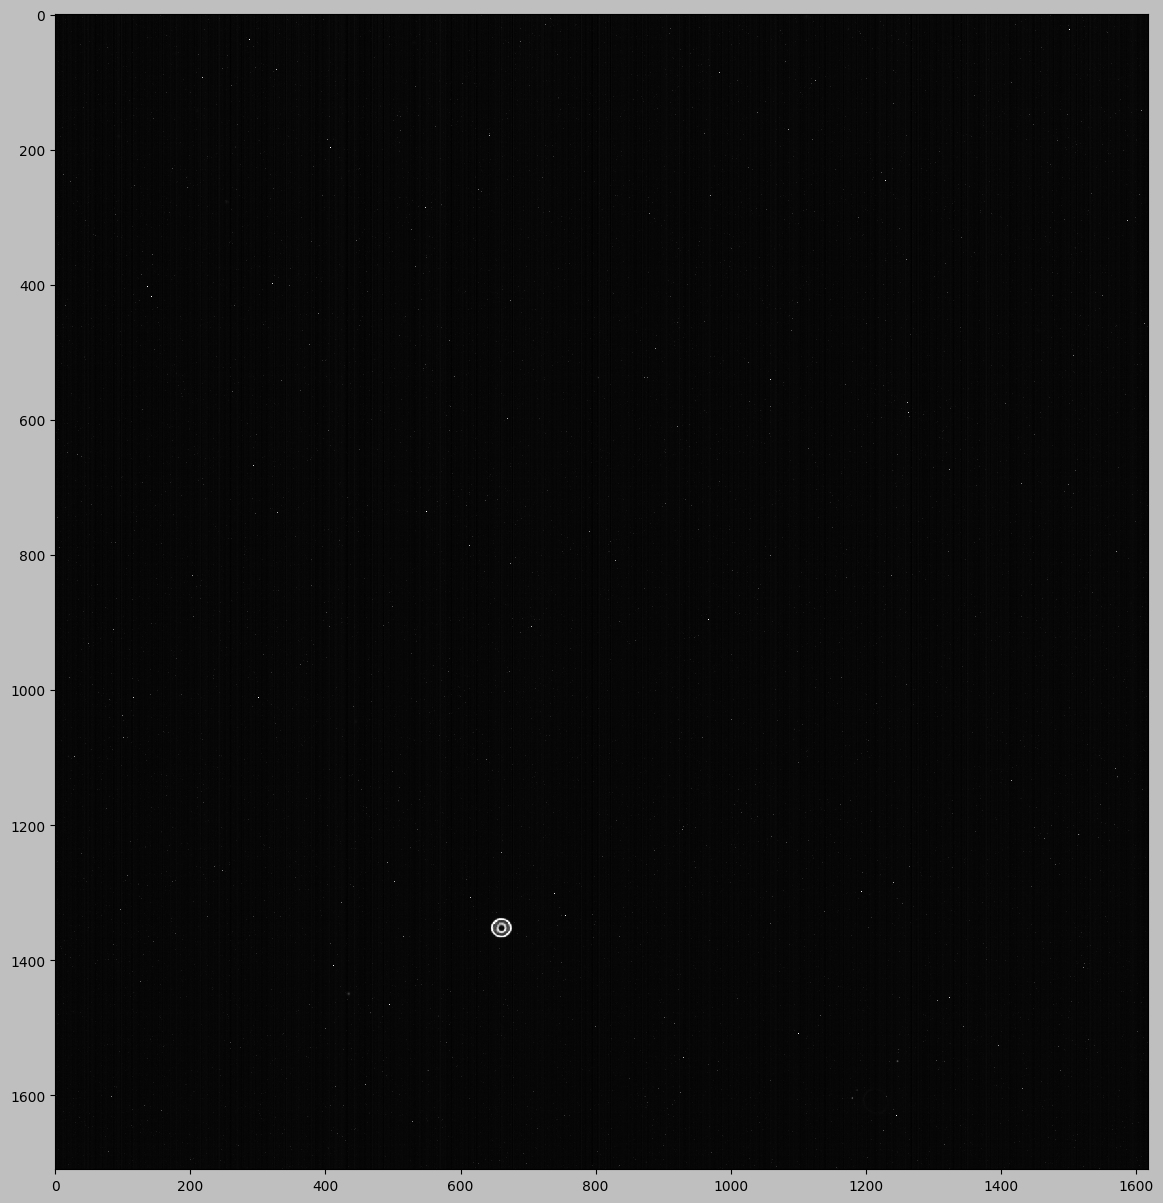

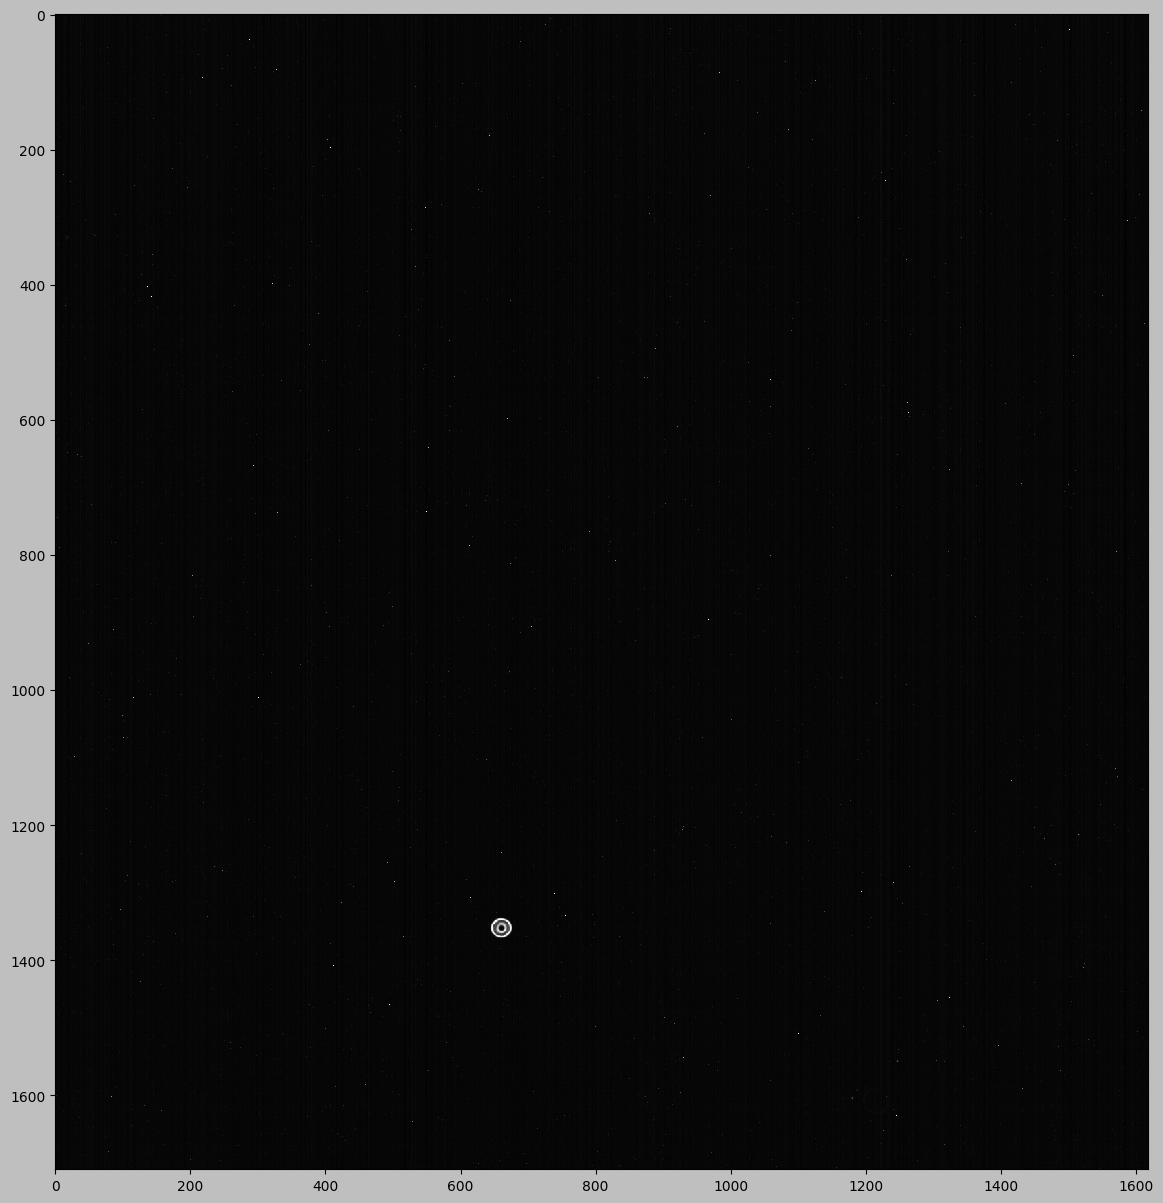

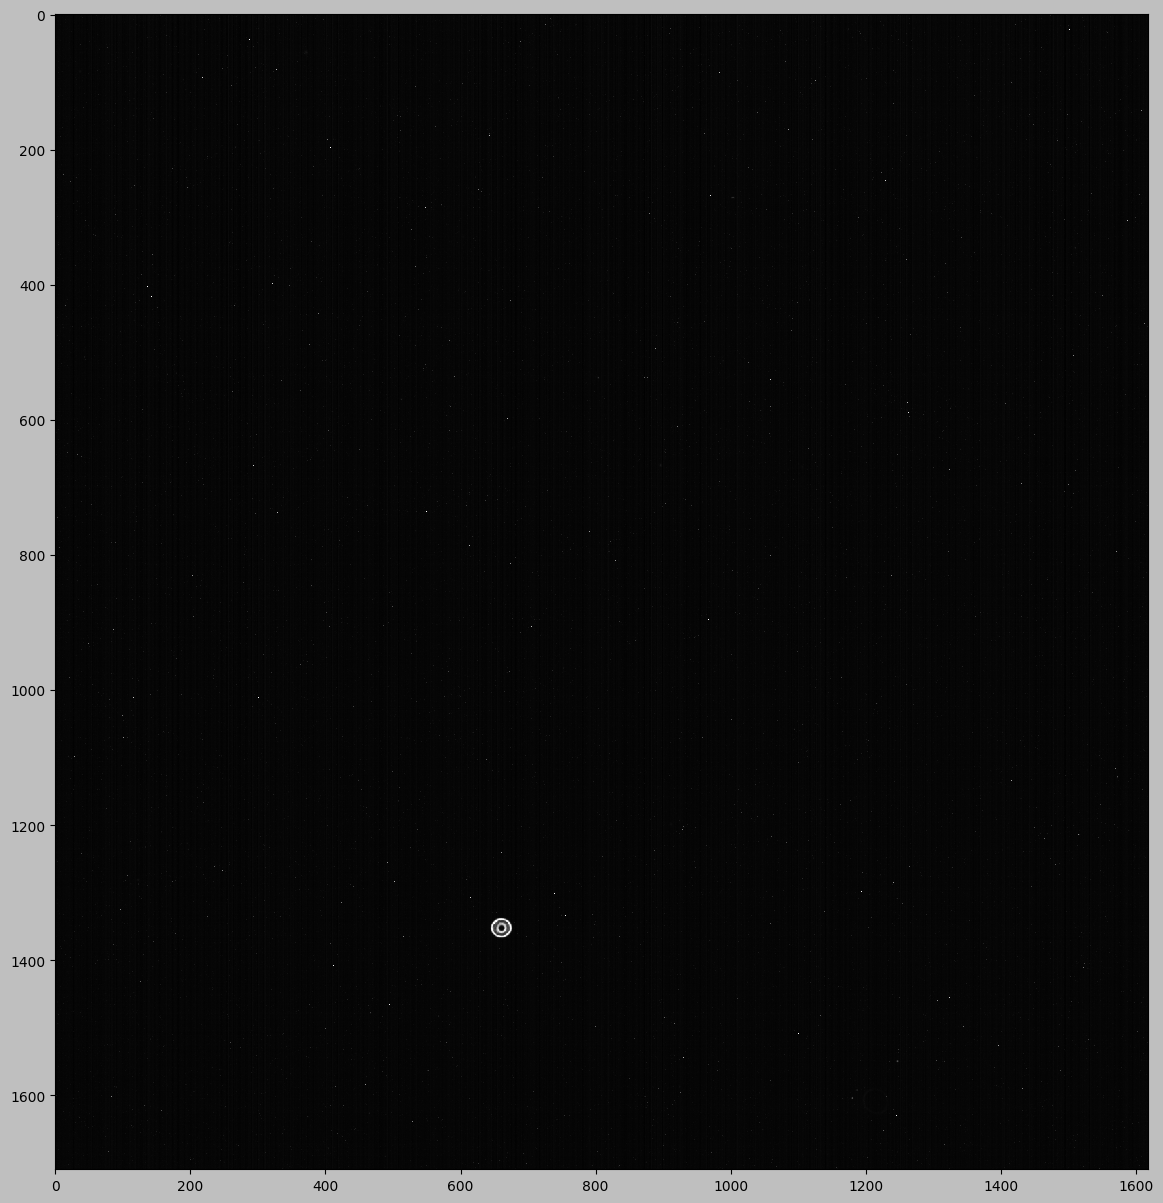

In [90]:
for img in files[:3]:
    fig = plt.figure(figsize=(15, 15))
    plt.imshow(img, interpolation='nearest')
    plt.grid(False)
    plt.show()

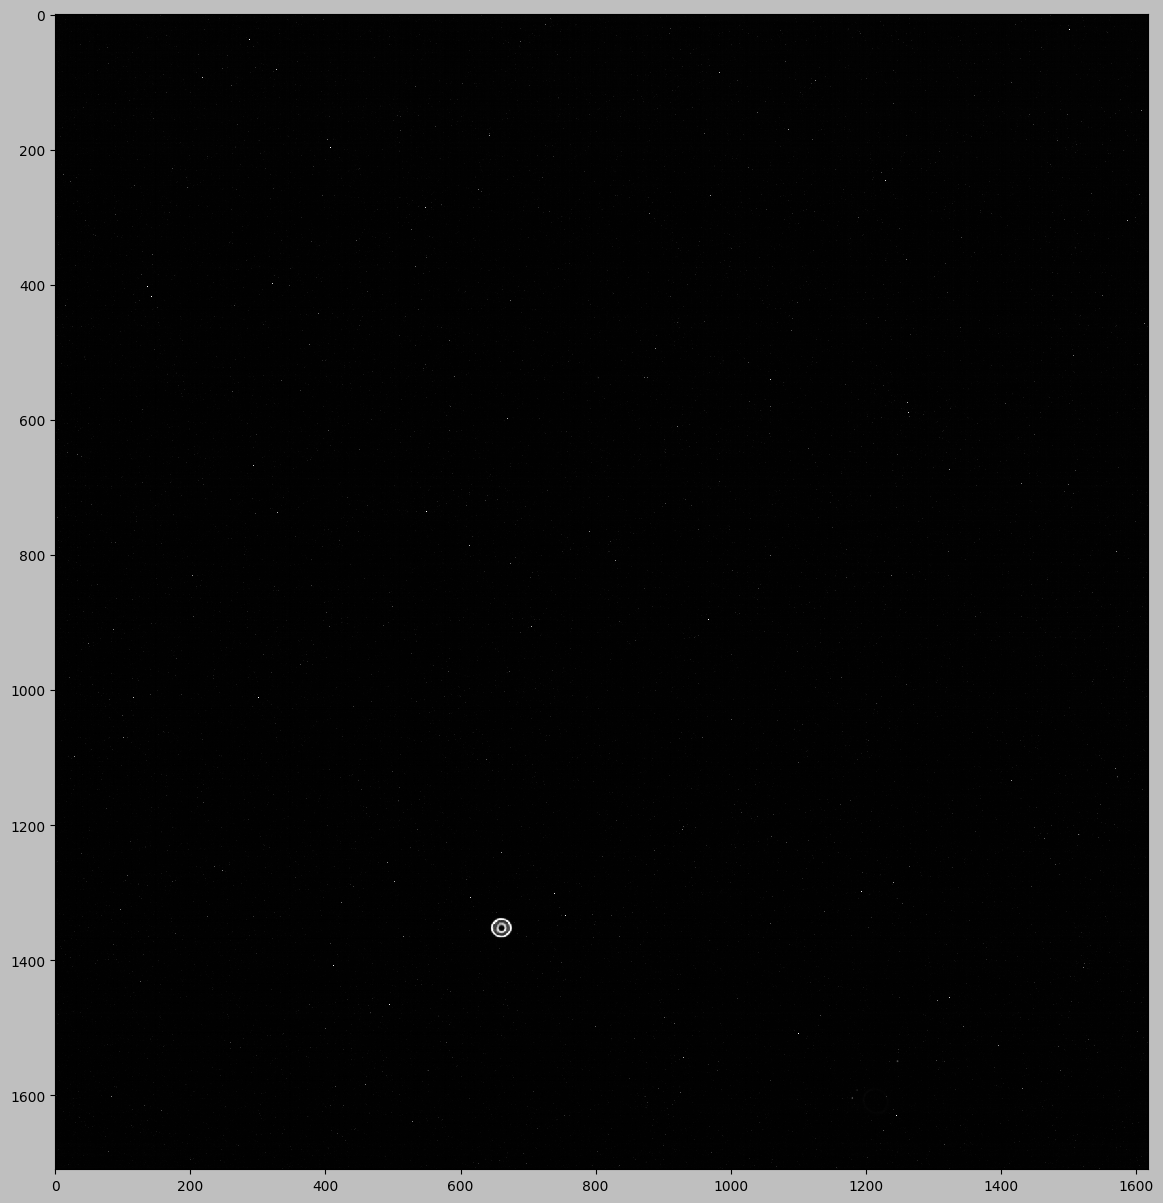

In [97]:
common_img = np.stack(files)
common_img = np.median(common_img, axis=0)
fig = plt.figure(figsize=(15, 15))
plt.imshow(common_img, interpolation='nearest')
plt.grid(False)
plt.show()

In [98]:
print(common_img.shape)
print(common_img.min(), common_img.max())
bncnt = np.bincount(common_img.astype('int64').flatten())

(1710, 1618)
78.5 4095.0


([<matplotlib.lines.Line2D at 0x2400f925a50>],)

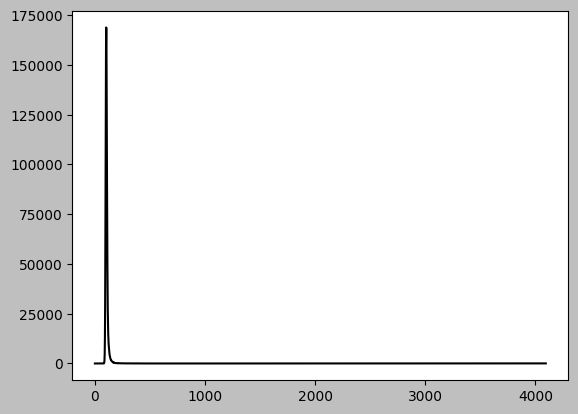

In [99]:
plt.plot(bncnt),

In [100]:
print(bncnt.argmax())

103


In [105]:
p99 = np.percentile(common_img, 99)
p99

np.float64(163.0)

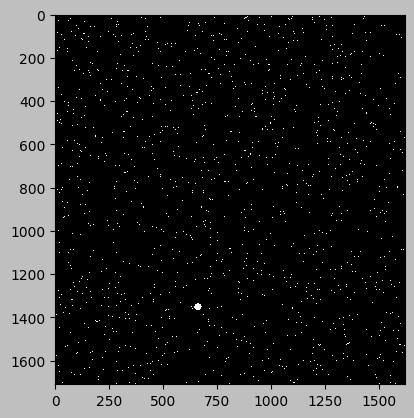

In [106]:
mask = common_img > p99
plt.imshow(mask, interpolation='nearest')